In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os.path
import sys
import warnings
warnings.simplefilter(action='ignore', category=pd.errors.PerformanceWarning)


# configuration
particles    = ['gamma','p+','e-','d','t','He3','a','e+','mu-','mu+','p-','n','an','pi+','pi-','pi0','kaon+','kaon-','Li','Be','B','C','N','O','F','Ne','Na','Mg','Al','Si','P','S','Cl','Ar','K','Ca','Sc','Ti','V','Cr','Mn','Fe','Co','Ni']
bins         = np.loadtxt('../phantom.bins')
energies     = bins[:-1]+0.5*np.diff(bins,1)
threshdic    = {"_0.000MeV":0.0,"_0.030MeV":0.03,"_0.060MeV":0.06,"_0.100MeV":0.1,"_0.300MeV":0.3}
shieldings   = ['zero_','five_','ten_','fifteen_','twenty_']


# Data loading and database formating
def phantom_loader(phantom_dfs,phantoms,shieldings,detectors,thresholds):
    print("starting phantom_loader()")
    for phantom in phantoms:
        for aShielding in shieldings:
            for aDetector in detectors:
                for aThreshold in thresholds:
                    fname       = phantom+aShielding+aThreshold+'_'+aDetector+'_response.txt'
                    #fnameAlt    = 'ramona_'+aShielding+aThreshold+'_'+aDetector+'_alt_response.txt' # generated from binaries
                    fnameVar    = phantom+aShielding+aThreshold+'_'+aDetector+'_variance.txt'
                    fnameEff    = phantom+aShielding+aThreshold+'_'+aDetector+'_counting.txt'
                    if os.path.isfile(fname):
                        data        = np.loadtxt(fname,skiprows=1)
                        #dataAlt     = np.loadtxt(fnameAlt,skiprows=1)
                        dataVar     = np.loadtxt(fnameVar,skiprows=1)
                        dataEff     = np.loadtxt(fnameEff,skiprows=1)
                        print(phantom,aShielding, aThreshold, "shapes",data.shape,dataVar.shape,dataEff.shape)
                        for aPartIndex in range(44):
                            df          = pd.DataFrame(data[aPartIndex,:],columns=['Relative ionization'])
                            #dfAlt       = pd.DataFrame(dataAlt[aPartIndex,:],columns=['Relative ionization Alt'])
                            dfVar       = pd.DataFrame(dataVar[aPartIndex,:],columns=['Variance / MeV'])
                            dfEff       = pd.DataFrame(dataEff[aPartIndex,:],columns=['Counting Efficiency'])
                            df.insert(loc=0,column='Shielding',value=aShielding)
                            df.insert(loc=1,column='Phantom',value=phantom)
                            df.insert(loc=2,column='Particles',value=particles[aPartIndex])
                            df.insert(loc=3,column='Threshold',value=aThreshold)
                            df.insert(loc=4,column='Energy / MeV',value=energies)
                            df = pd.concat([df,dfVar,dfEff],axis=1)
                            phantom_dfs.append(df)
    return phantom_dfs


phantom_dfs = []
phantom_dfs = phantom_loader(phantom_dfs,['ramona_','flatramona_','realramona_'],shieldings,['detA'],['0.060MeV'])
phantom_dfs = phantom_loader(phantom_dfs,['icru_'],shieldings,['detAB'],['0.000MeV'])
df = pd.concat(phantom_dfs)
df = df.set_index(['Phantom','Shielding','Particles'])
#print(df)
print(df.info(memory_usage="deep"))
df




starting phantom_loader()
ramona_ zero_ 0.060MeV shapes (44, 650) (44, 650) (44, 650)
ramona_ five_ 0.060MeV shapes (44, 650) (44, 650) (44, 650)
ramona_ ten_ 0.060MeV shapes (44, 650) (44, 650) (44, 650)
ramona_ fifteen_ 0.060MeV shapes (44, 650) (44, 650) (44, 650)
ramona_ twenty_ 0.060MeV shapes (44, 650) (44, 650) (44, 650)
flatramona_ zero_ 0.060MeV shapes (44, 650) (44, 650) (44, 650)
flatramona_ five_ 0.060MeV shapes (44, 650) (44, 650) (44, 650)
flatramona_ ten_ 0.060MeV shapes (44, 650) (44, 650) (44, 650)
flatramona_ fifteen_ 0.060MeV shapes (44, 650) (44, 650) (44, 650)
flatramona_ twenty_ 0.060MeV shapes (44, 650) (44, 650) (44, 650)
realramona_ zero_ 0.060MeV shapes (44, 650) (44, 650) (44, 650)
realramona_ five_ 0.060MeV shapes (44, 650) (44, 650) (44, 650)
realramona_ ten_ 0.060MeV shapes (44, 650) (44, 650) (44, 650)
realramona_ fifteen_ 0.060MeV shapes (44, 650) (44, 650) (44, 650)
realramona_ twenty_ 0.060MeV shapes (44, 650) (44, 650) (44, 650)
starting phantom_loade

Threshold  Energy / MeV  Relative ionization  \
Phantom Shielding Particles                                                
ramona_ zero_     gamma      0.060MeV  1.023564e-06                 0.00   
                  gamma      0.060MeV  1.071803e-06                 0.00   
                  gamma      0.060MeV  1.122316e-06                 0.00   
                  gamma      0.060MeV  1.175209e-06                 0.00   
                  gamma      0.060MeV  1.230595e-06                 0.00   
...                               ...           ...                  ...   
icru_   twenty_   Ni         0.000MeV  8.130460e+06             14172.34   
                  Ni         0.000MeV  8.513637e+06             14250.95   
                  Ni         0.000MeV  8.914872e+06             14354.11   
                  Ni         0.000MeV  9.335017e+06             14415.36   
                  Ni         0.000MeV  9.774963e+06             14512.17   

                             Variance / MeV  Counting Efficiency  
Phantom Shielding Particles                                       
ramona_ zero_     gamma                0.00             0.000000  
                  gamma                0.00             0.000000  
                  gamma                0.00             0.000000  
                  gamma                0.00             0.000000  
                  gamma                0.00             0.000000  
...                                     ...                  ...  
icru_   twenty_   Ni               10200.41             0.999867  
                  Ni               10239.76             0.999913  
                  Ni               10302.70             0.999856  
                  Ni               10354.94             0.999891  
                  Ni               10396.29             0.999890  

[572000 rows x 5 columns]

0 0 mm p+ [0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0

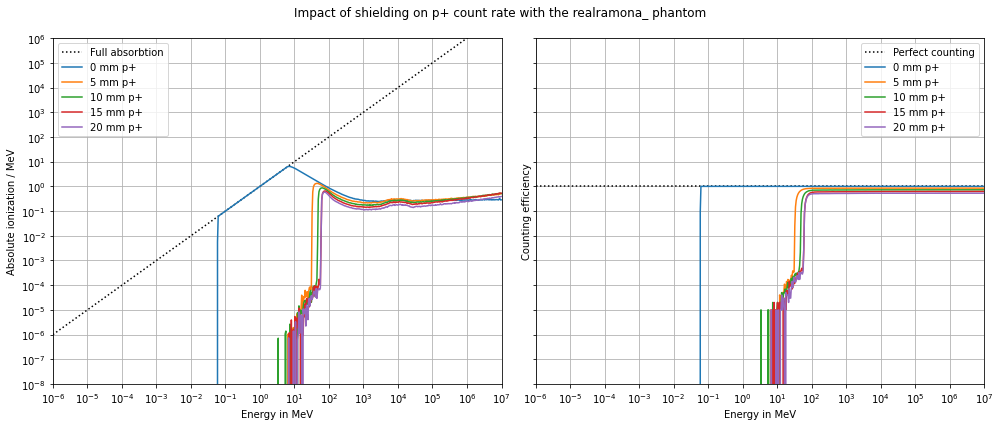

In [27]:
def conf_axis(ax1):
    ax1.legend()
    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.grid()
    ax1.set_xticks(10**np.linspace(-6,7,14))
    ax1.set_xlim(1e-6,1e7)
    ax1.set_yticks(10**np.linspace(-8,6,15))
    ax1.set_ylim(1e-8,1e6)
    

# generalized response plot routine
def alt_plot(datas,labels,title,method=' Alt'):
    fig, axes = plt.subplots(ncols=2,figsize=(14,6),sharey=True)
    ax1, ax2  = axes
    #ax1.plot([1e-6,1e7],[threshold,threshold],label='DOSTEL $E_{MIN}$',color='m',ls=':')
    ax1.plot([1e-6,1e7],[1e-6,1e7],label='Full absorbtion',color='k',ls=':')
    ax2.plot([1e-6,1e7],[1,1],label='Perfect counting',color='k',ls=':')
    for k in range(len(datas)):
        data     = datas[k]
        label    = labels[k]
        absolute = data['Relative ionization']
        effic    = data['Counting Efficiency']
        print(k,label,effic.values)
        #print(relative)
        ax1.set_ylabel('Absolute ionization / MeV')
        ax1.plot(data['Energy / MeV'],absolute,label=label)
        ax2.set_ylabel('Counting efficiency')
        ax2.plot(data['Energy / MeV'],effic,label=label)
        #ax1.fill_between(data['Energy / MeV'][mask],(absolute-absvar)[mask],(absolute+absvar)[mask],alpha=0.1)
        #ax1.plot(data['Energy / MeV'],(absolute+absvar),alpha=0.5,ls='--')
    conf_axis(ax1)
    conf_axis(ax2)
    ax1.set_xlabel('Energy in MeV')
    ax2.set_xlabel('Energy in MeV')
    fig.suptitle(title)
    plt.tight_layout()
    fig.savefig(title+".pdf")
    plt.show()


    
def comp_shield(part,phantom):
    # This function is for comparison of different shielding thicknesses
    alt_plot([df.loc[phantom,'zero_',part],
              df.loc[phantom,'five_',part],
              df.loc[phantom,'ten_',part],
              df.loc[phantom,'fifteen_',part],
              df.loc[phantom,'twenty_',part]],
             ["0 mm "+part,"5 mm "+part,"10 mm "+part,"15 mm "+part,"20 mm "+part],"Impact of shielding on %s count rate with the %s phantom"%(part,phantom))

def comp_phantoms(part,shielding):
    alt_plot([df.loc['ramona_',shielding,part],
              df.loc['flatramona_',shielding,part],
              df.loc['realramona_',shielding,part],
              df.loc['icru_',shielding,part]],
             [shielding+' ramona '+part,shielding+' flatramona '+part,shielding+' realramona '+part,shielding+' icru '+part],"Comparison of phantoms with %s and %s shielding"%(part,shielding))

comp_shield('p+','realramona_')

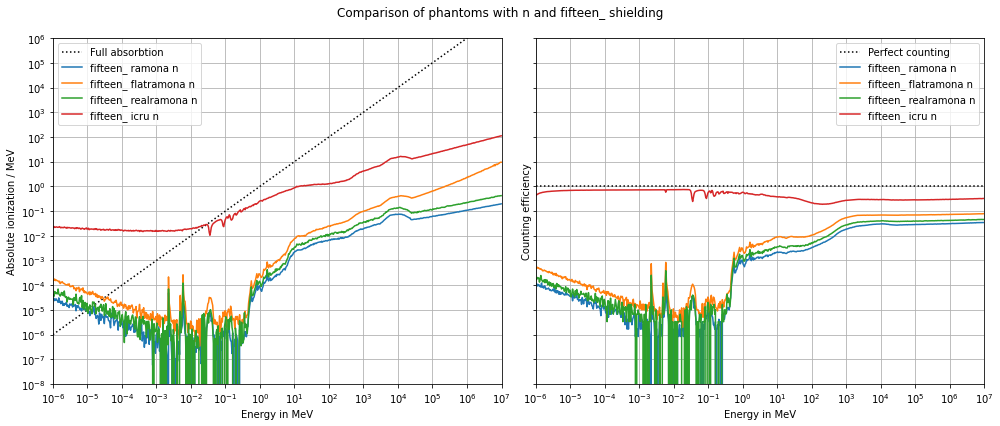

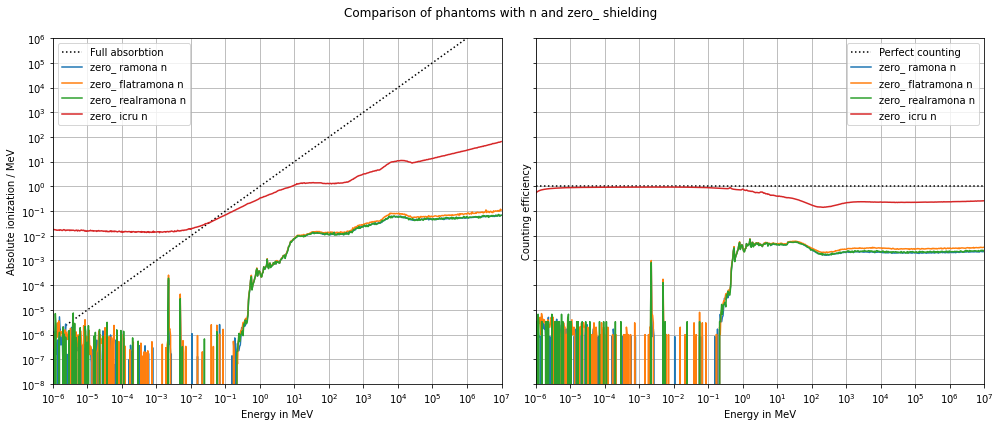

In [12]:
#comp_shield("n",'ramona_')
comp_phantoms('n','fifteen_')
comp_phantoms('n','zero_')


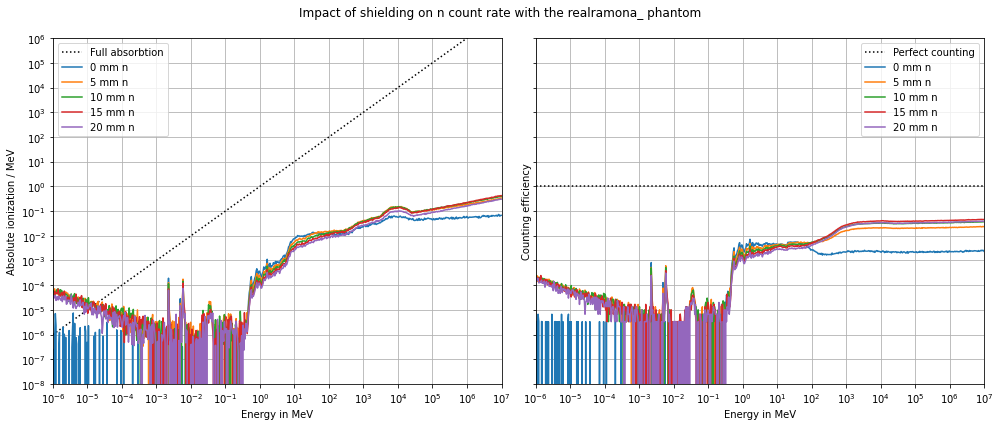

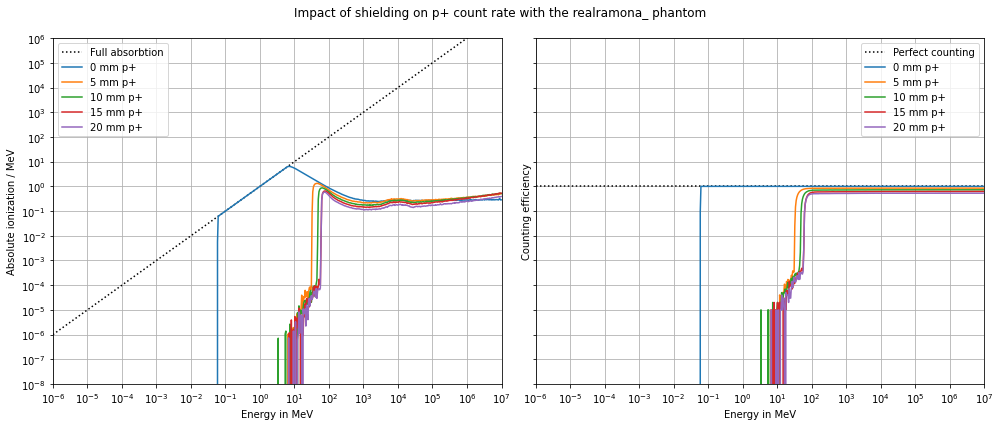

In [22]:
comp_shield('n','realramona_')
comp_shield('p+','realramona_')

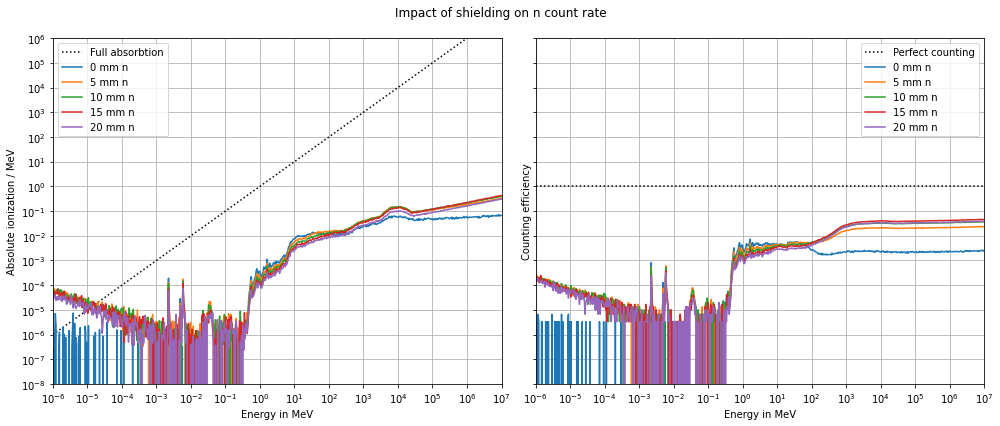